# Homework 8: Mini Diffusion Model

MNIST, 100 diffusion steps, and one noise predictor shared by DDPM and DDIM.

## Setup

Images are scaled to [-1, 1]. Training uses all 60,000 MNIST training images, batch size 128, and 50 epochs. The random seed is 6812. Install the packages in `requirements.txt` before running this notebook.

In [1]:
from pathlib import Path
import json
import time
import random
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torchvision.datasets import MNIST
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

SEED = 6812
T = 100
OUT = Path('hw8_outputs')
OUT.mkdir(exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def seed_all(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.set_num_threads(4)

def schedule(device=DEVICE):
    beta = torch.cat([torch.zeros(1), torch.linspace(0.0001, 0.02, T)]).to(device)
    alpha = 1 - beta
    abar = alpha.cumprod(0)
    return beta, alpha, abar

def extract(values, t):
    return values[t].view(-1, 1, 1, 1)

def q_sample(x0, t, noise, abar):
    a = extract(abar, t)
    return a.sqrt() * x0 + (1 - a).sqrt() * noise

class MiniCNN(nn.Module):
    """Eight convolutions, timestep embeddings, and two spatial resolutions."""
    def __init__(self):
        super().__init__()
        self.time = nn.Sequential(nn.Embedding(T + 1, 64), nn.Linear(64, 64), nn.SiLU())
        self.c1 = nn.Conv2d(1, 32, 3, padding=1)
        self.c2 = nn.Conv2d(32, 32, 3, padding=1)
        self.down = nn.Conv2d(32, 64, 3, stride=2, padding=1)
        self.c3 = nn.Conv2d(64, 64, 3, padding=1)
        self.c4 = nn.Conv2d(64, 64, 3, padding=1)
        self.up = nn.Conv2d(64, 32, 3, padding=1)
        self.c5 = nn.Conv2d(64, 32, 3, padding=1)
        self.out = nn.Conv2d(32, 1, 3, padding=1)
        self.t32 = nn.Linear(64, 32)
        self.t64 = nn.Linear(64, 64)

    def forward(self, x, t):
        emb = self.time(t)
        e32 = self.t32(emb)[:, :, None, None]
        e64 = self.t64(emb)[:, :, None, None]
        h = F.silu(self.c1(x) + e32)
        skip = F.silu(self.c2(h))
        h = F.silu(self.down(skip) + e64)
        h = F.silu(self.c3(h))
        h = F.silu(self.c4(h) + h)
        h = F.interpolate(h, size=skip.shape[-2:], mode='nearest')
        h = F.silu(self.up(h) + e32)
        return self.out(F.silu(self.c5(torch.cat([h, skip], dim=1))))

## (a) Forward diffusion

Let $\alpha_t=1-\beta_t$ and $\bar\alpha_t=\prod_{s=1}^t\alpha_s$. The schedule increases linearly from 0.0001 to 0.02 over 100 steps. I sample a noisy image directly using

$$x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\epsilon,\qquad \epsilon\sim\mathcal N(0,I).$$

Index 0 represents the clean image, so $\bar\alpha_0=1$. The plot reuses one noise draw to make the changing noise level easier to see; it is not a simulated Markov trajectory.

In [2]:
def forward_plot(data):
    _, _, abar = schedule('cpu')
    x0 = data[0:1].float().unsqueeze(1) / 127.5 - 1
    noise = torch.randn_like(x0)
    steps = [0, 1, 10, 25, 50, 75, 100]
    fig, axes = plt.subplots(1, len(steps), figsize=(12, 2.1))
    for ax, t in zip(axes, steps):
        xt = q_sample(x0, torch.tensor([t]), noise, abar)
        ax.imshow(xt[0, 0], cmap='gray', vmin=-1, vmax=1)
        ax.set_title(f't = {t}')
        ax.axis('off')
    fig.suptitle('Forward diffusion (same noise draw at each timestep)')
    fig.tight_layout()
    fig.savefig(OUT / 'forward_diffusion.png', dpi=160)
    plt.close(fig)

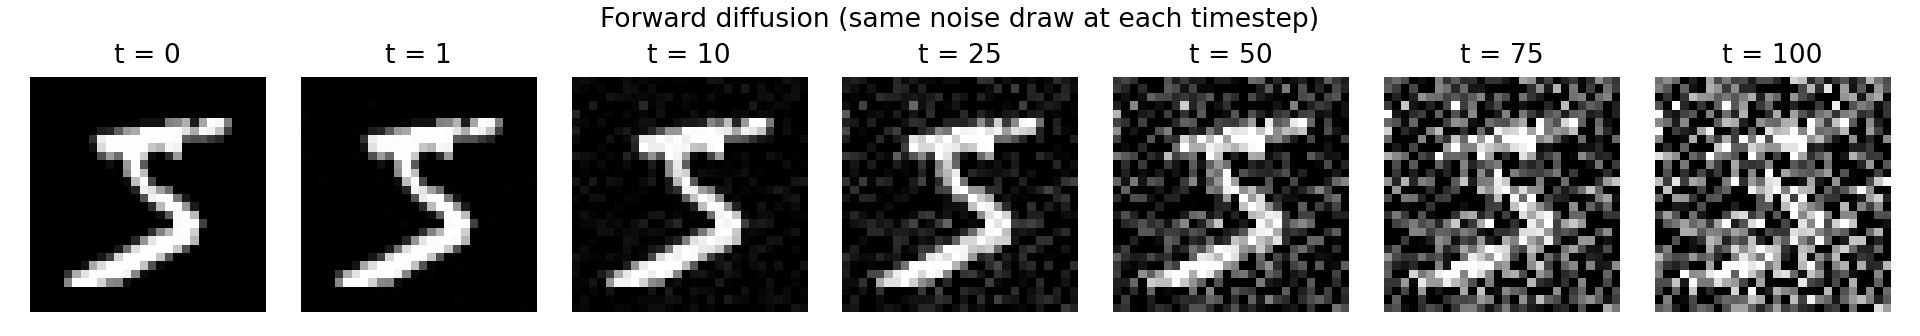

Final alpha_bar: 0.3635632395744324


In [3]:
seed_all()
dataset = MNIST('hw8_data', train=True, download=True)
forward_plot(dataset.data)
from IPython.display import display, Image
display(Image(filename=str(OUT / 'forward_diffusion.png')))
print('Final alpha_bar:', schedule('cpu')[2][-1].item())

## (b) Training the noise predictor

The CNN has eight convolutional layers with SiLU activations. A learned timestep embedding is added to the feature maps. It reduces the spatial resolution from 28×28 to 14×14, then upsamples and combines the features with a skip connection. Its output has shape `(batch, 1, 28, 28)`, matching the noise target.

Each training batch gets new Gaussian noise and independently sampled timesteps from 1 through 100. Adam minimizes $\mathbb E[\|\epsilon-\epsilon_\theta(x_t,t)\|^2]$, averaged over the pixels and batch. The plotted epoch loss is weighted by batch size.

The training cell resumes an existing checkpoint. In a fresh directory it trains all 50 epochs; remove `hw8_outputs/checkpoint.pt` to start over.

In [4]:
def train(epochs=50):
    seed_all()
    dataset = MNIST('hw8_data', train=True, download=True)
    forward_plot(dataset.data)
    # Keep normalized images on GPU to avoid repeated CPU data conversion.
    data = dataset.data.unsqueeze(1).to(DEVICE, dtype=torch.float32) / 127.5 - 1
    model = MiniCNN().to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=0.001)
    _, _, abar = schedule()
    history = []
    start_epoch = 0
    checkpoint = OUT / 'checkpoint.pt'
    if checkpoint.exists():
        state = torch.load(checkpoint, map_location=DEVICE, weights_only=True)
        model.load_state_dict(state['model'])
        opt.load_state_dict(state['optimizer'])
        history = state['loss']
        start_epoch = len(history)
        torch.set_rng_state(state['rng'].cpu())
        if DEVICE.type == 'cuda':
            torch.cuda.set_rng_state(state['cuda_rng'].cpu())
    model.train()
    for epoch in range(start_epoch, epochs):
        start = time.perf_counter()
        total = 0.0
        order = torch.randperm(len(data), device=DEVICE)
        for ids in order.split(128):
            x0 = data[ids]
            t = torch.randint(1, T + 1, (len(ids),), device=DEVICE)
            eps = torch.randn_like(x0)
            prediction = model(q_sample(x0, t, eps, abar), t)
            loss = F.mse_loss(prediction, eps)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            total += loss.item() * len(ids)
        history.append(total / len(data))
        torch.save({'model': model.state_dict(), 'optimizer': opt.state_dict(),
                    'loss': history, 'rng': torch.get_rng_state(),
                    'cuda_rng': torch.cuda.get_rng_state() if DEVICE.type == 'cuda' else torch.get_rng_state()}, checkpoint)
        print(f'Epoch {epoch + 1:02d}/{epochs}: MSE={history[-1]:.6f}, {time.perf_counter()-start:.1f}s', flush=True)
    fig, ax = plt.subplots(figsize=(7, 4))
    ax.plot(range(1, len(history) + 1), history)
    ax.set(xlabel='Epoch', ylabel='Mean noise-prediction MSE', title='Training on 60,000 MNIST images')
    ax.grid(alpha=0.2)
    fig.tight_layout()
    fig.savefig(OUT / 'training_loss.png', dpi=160)
    plt.close(fig)
    return model.eval(), history

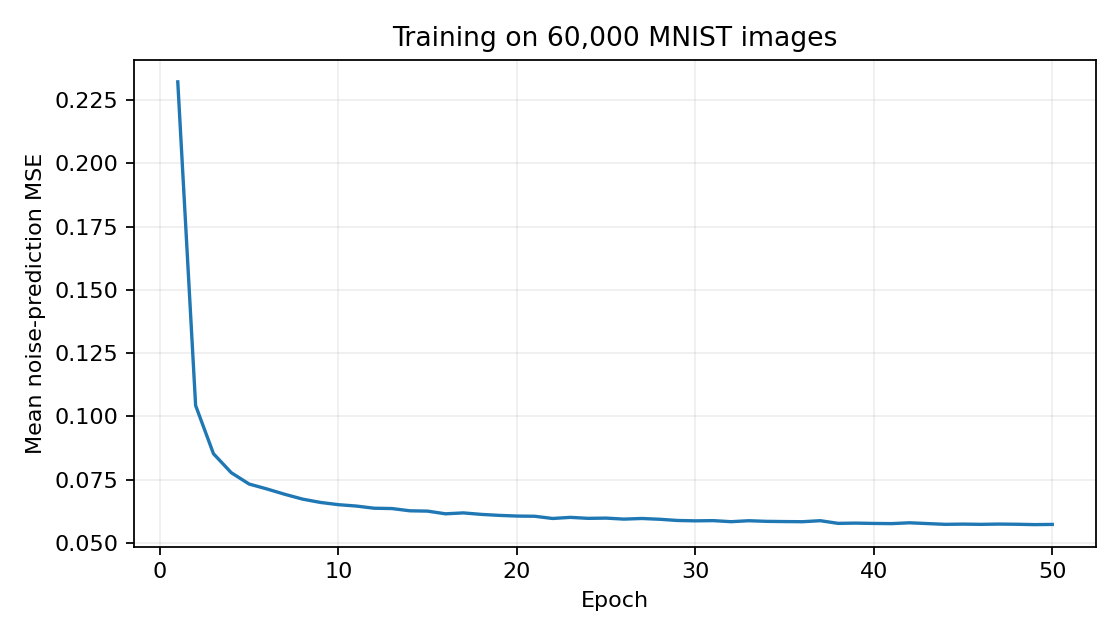

Epochs: 50, first MSE: 0.232206, last MSE: 0.057280


In [5]:
model, history = train(epochs=50)
display(Image(filename=str(OUT / 'training_loss.png')))
print(f'Epochs: {len(history)}, first MSE: {history[0]:.6f}, last MSE: {history[-1]:.6f}')

## (c) DDPM sampling

Starting at $x_{100}\sim\mathcal N(0,I)$, the reverse mean is

$$\mu_\theta(x_t,t)=\frac{1}{\sqrt{\alpha_t}}\left(x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\epsilon_\theta(x_t,t)\right).$$

I use the fixed posterior variance $\tilde\beta_t=\beta_t(1-\bar\alpha_{t-1})/(1-\bar\alpha_t)$ and set $x_{t-1}=\mu_\theta+\sqrt{\tilde\beta_t}z$. Fresh Gaussian noise is added for $t>1$. The last step has no added noise.

In [6]:
@torch.no_grad()
def ddpm(model, initial):
    beta, alpha, abar = schedule(initial.device)
    x = initial.clone()
    for t in range(T, 0, -1):
        ts = torch.full((len(x),), t, device=x.device, dtype=torch.long)
        eps = model(x, ts)
        mean = (x - beta[t] / (1 - abar[t]).sqrt() * eps) / alpha[t].sqrt()
        variance = beta[t] * (1 - abar[t-1]) / (1 - abar[t])
        x = mean + variance.sqrt() * torch.randn_like(x) if t > 1 else mean
    return x

## (d) DDIM sampling

DDIM uses the same trained network. For a selected timestep $t$ and the next smaller timestep $s$, I estimate

$$\hat x_0=\frac{x_t-\sqrt{1-\bar\alpha_t}\epsilon_\theta(x_t,t)}{\sqrt{\bar\alpha_t}},\qquad x_s=\sqrt{\bar\alpha_s}\hat x_0+\sqrt{1-\bar\alpha_s}\epsilon_\theta(x_t,t).$$

This is deterministic DDIM ($\eta=0$). The selected timesteps are rounded, evenly spaced points from 100 to 1; the final update goes to 0. The 50-step and 20-step versions therefore make exactly 50 and 20 network calls. No retraining is needed.

Each sampler starts with the same batch of 32 Gaussian images. Values are clipped only for display, not during the reverse process. Timings cover sampling on the reported device and exclude plotting.

In [7]:
@torch.no_grad()
def ddim(model, initial, steps):
    _, _, abar = schedule(initial.device)
    # Exactly `steps` model evaluations; the last transition ends at clean t=0.
    times = torch.linspace(T, 1, steps).round().long().tolist()
    x = initial.clone()
    for t, prev in zip(times, times[1:] + [0]):
        ts = torch.full((len(x),), t, device=x.device, dtype=torch.long)
        eps = model(x, ts)
        x0 = (x - (1 - abar[t]).sqrt() * eps) / abar[t].sqrt()
        x = abar[prev].sqrt() * x0 + (1 - abar[prev]).sqrt() * eps
    return x

def compare(model, history):
    seed_all(SEED + 1)
    initial = torch.randn(32, 1, 28, 28, device=DEVICE)
    results, timings = {}, {}
    # Warm up CUDA before timing the full batches.
    with torch.no_grad():
        model(initial, torch.full((32,), T, device=DEVICE, dtype=torch.long))
    for name, sampler in [('DDPM (100 steps)', lambda: ddpm(model, initial)),
                          ('DDIM (50 steps)', lambda: ddim(model, initial, 50)),
                          ('DDIM (20 steps)', lambda: ddim(model, initial, 20))]:
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        start = time.perf_counter()
        samples = sampler()
        if DEVICE.type == 'cuda': torch.cuda.synchronize()
        timings[name] = time.perf_counter() - start
        results[name] = samples.cpu()
        assert torch.isfinite(samples).all()
    fig, axes = plt.subplots(6, 16, figsize=(16, 7))
    for group, (name, samples) in enumerate(results.items()):
        for i in range(32):
            ax = axes[2 * group + i // 16, i % 16]
            ax.imshow(samples[i, 0].clamp(-1, 1), cmap='gray', vmin=-1, vmax=1)
            ax.axis('off')
        axes[2 * group, 0].set_title(name, loc='left', fontsize=12, pad=10)
    fig.suptitle('Same starting Gaussian noise for all three samplers', fontsize=14)
    fig.tight_layout()
    fig.savefig(OUT / 'sampling_comparison.png', dpi=180)
    plt.close(fig)
    torch.save({'initial': initial.cpu(), 'samples': results}, OUT / 'samples.pt')
    metrics = {'seed': SEED, 'epochs': len(history), 'batch_size': 128,
               'train_images': 60000, 'loss': history, 'sampling_seconds_32_images': timings,
               'alpha_bar_T': schedule('cpu')[2][-1].item(),
               'parameters': sum(p.numel() for p in model.parameters()),
               'device': torch.cuda.get_device_name() if DEVICE.type == 'cuda' else 'CPU',
               'torch_version': str(torch.__version__)}
    (OUT / 'metrics.json').write_text(json.dumps(metrics, indent=2))
    print(json.dumps({k: v for k, v in metrics.items() if k != 'loss'}, indent=2), flush=True)
    return metrics

{
  "seed": 6812,
  "epochs": 50,
  "batch_size": 128,
  "train_images": 60000,
  "sampling_seconds_32_images": {
    "DDPM (100 steps)": 0.37273060000734404,
    "DDIM (50 steps)": 0.16441590001340955,
    "DDIM (20 steps)": 0.08077729999786243
  },
  "alpha_bar_T": 0.3635632395744324,
  "parameters": 156001,
  "device": "NVIDIA GeForce GTX 1650",
  "torch_version": "2.6.0+cu124"
}


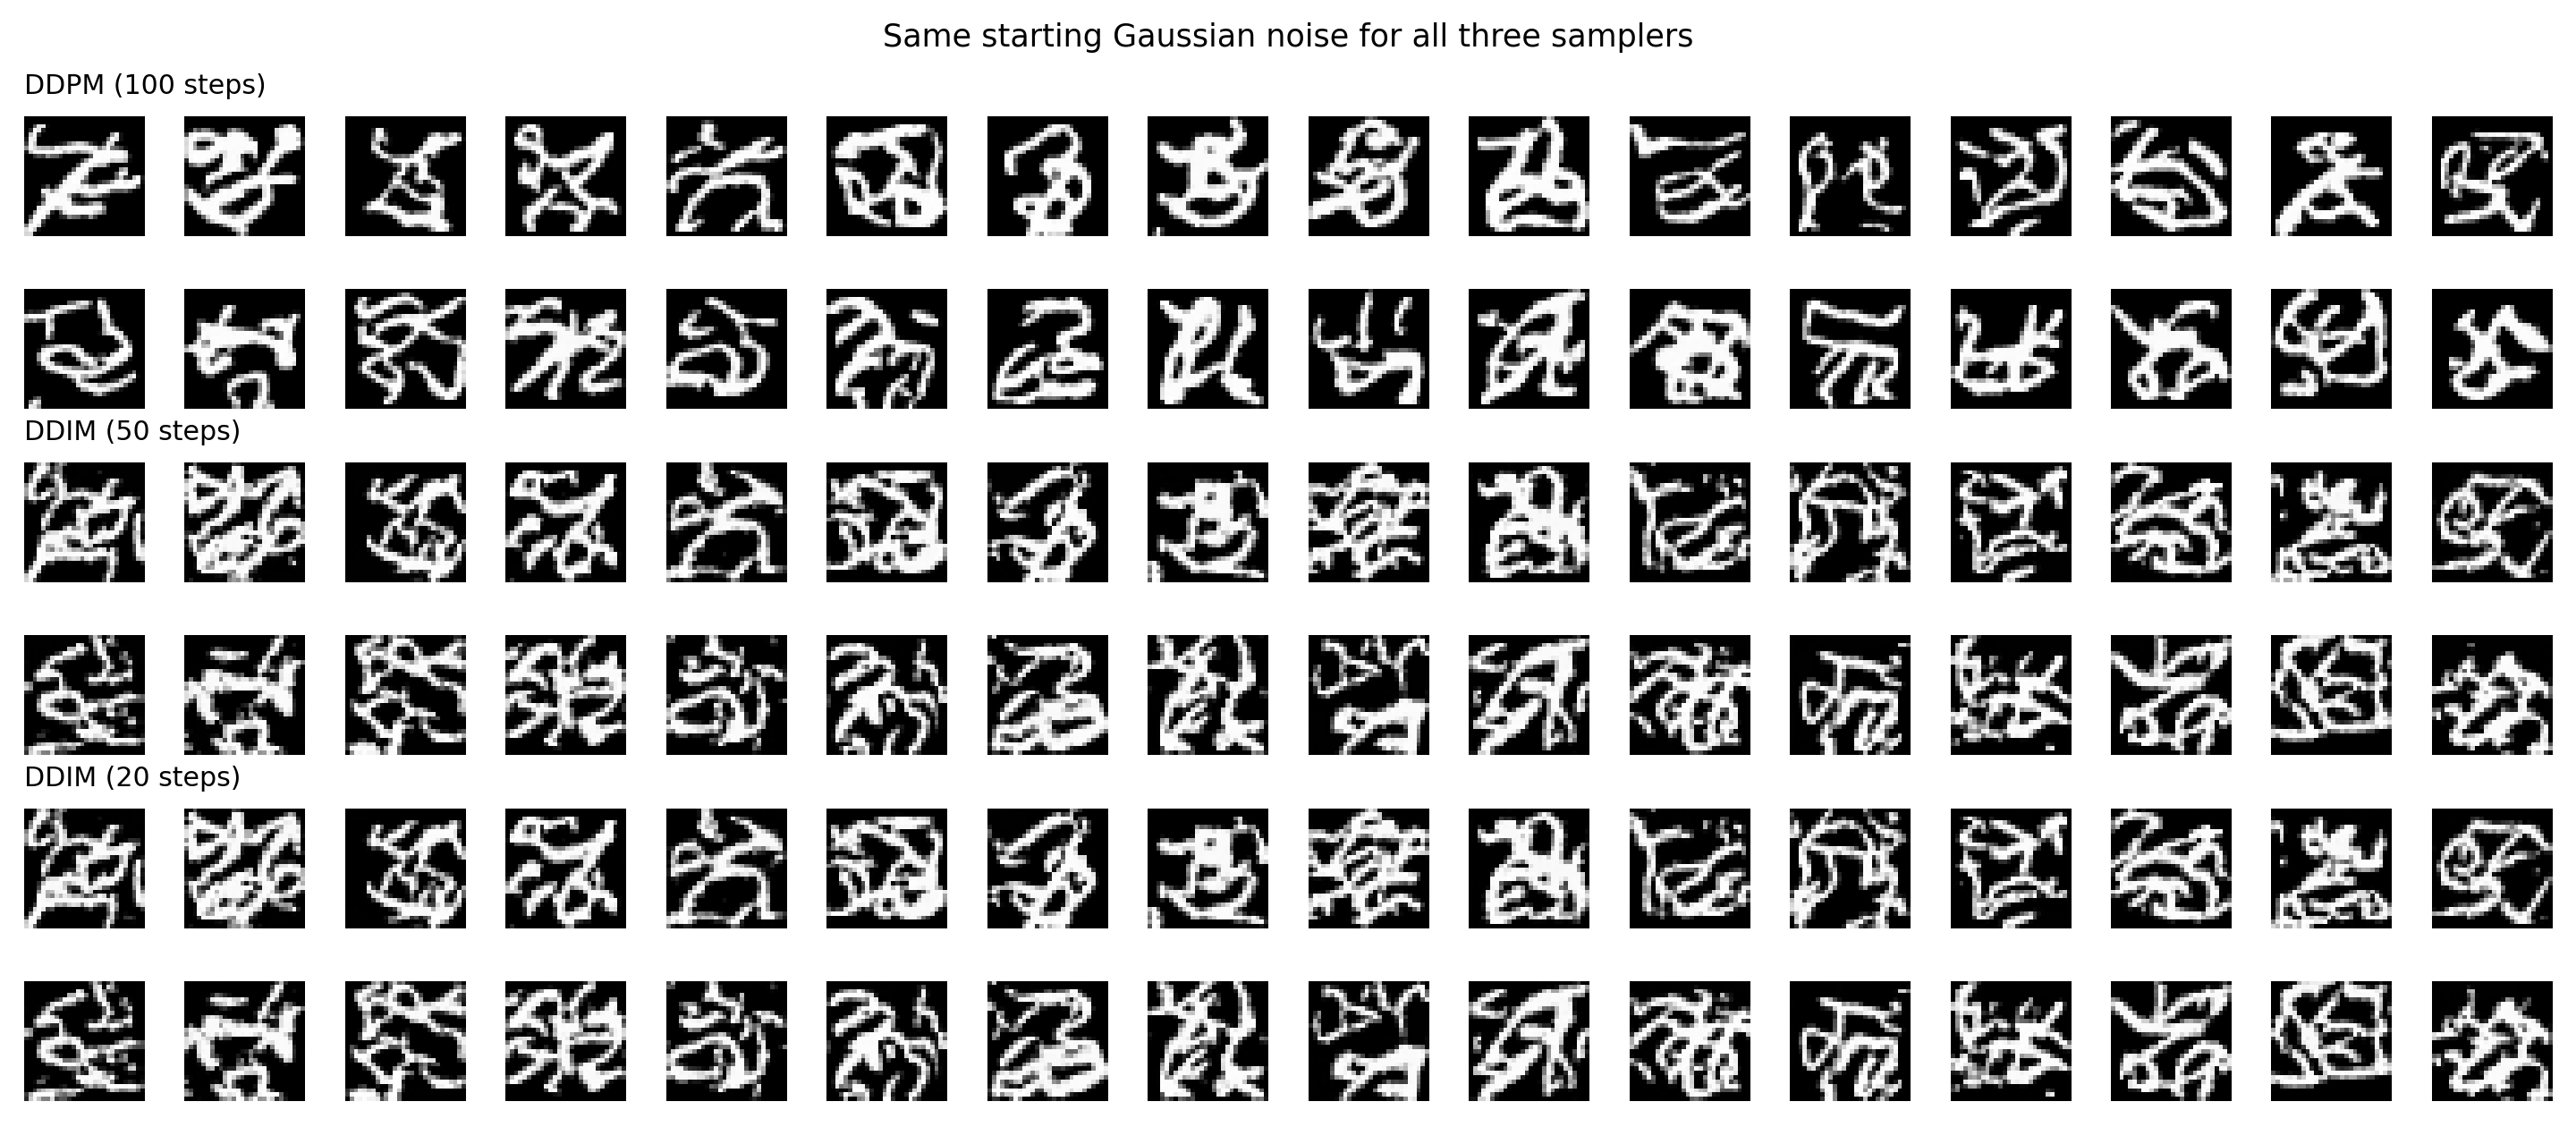

In [8]:
metrics = compare(model, history)
display(Image(filename=str(OUT / 'sampling_comparison.png')))

## Discussion

The training loss dropped from **0.2322 in the first epoch to 0.0573 in epoch 50**. Most of the improvement happened early: by epoch 10, the loss was already 0.0651. After that, the curve flattened, with small fluctuations because each batch received newly sampled noise and timesteps. This shows that the network learned to predict much of the added noise, but it does not measure how convincing its generated digits are.

The generated images are the weaker part of this experiment. They have bright strokes and dark backgrounds, but many contain overlapping loops or extra branches instead of a readable digit. In this grid, DDPM tends to produce more solid strokes and fewer small fragments than DDIM. That is a visual observation from these 32 samples, not a measured image-quality score.

The two DDIM grids look very similar when comparing the same positions. Reducing the steps from 50 to 20 changes some edges and small details, but neither version solves the distorted shapes. I would not conclude from these results that 20 steps always gives the same quality as 50; both are limited by this model and training setup.

| Sampler | Network evaluations | Time for 32 images | Speed relative to DDPM |
| --- | ---: | ---: | ---: |
| DDPM | 100 | 0.373 s | 1.00× |
| DDIM | 50 | 0.164 s | 2.27× |
| DDIM | 20 | 0.081 s | 4.61× |

These are single-run timings on the GTX 1650 after a warm-up, with CUDA synchronization before and after sampling. They exclude plotting. The main benefit of DDIM here is lower sampling cost: it reuses the trained model while making fewer predictions. DDPM introduces new randomness during the reverse process; DDIM with eta equal to zero does not.

There is also a limitation in the assigned schedule. At step 100, **alpha-bar is about 0.3636**, so the coefficient on the original image is still about 0.603. The forward plot confirms that the digit has not disappeared. Training therefore ends with noisy images that retain substantial structure, while generation is required to start from pure Gaussian noise. That mismatch is a plausible contributor to the poor shapes, alongside the small network. This experiment does not isolate how much each factor contributes. The required schedule was kept unchanged.

The implementation demonstrates the difference between the two sampling procedures, but the samples are not clean MNIST-quality digits. A follow-up experiment could test a schedule whose terminal alpha-bar is closer to zero and a model that captures more of the whole image at once. Those changes were not used in the submitted comparison.

## Checks

The equation checks passed for the forward process, the clean endpoint, and both reverse samplers. With an exact noise predictor constructed from a known clean image, DDPM and DDIM recovered that image within floating-point tolerance. The checks also confirmed 100, 50, and 20 model evaluations, deterministic DDIM output for fixed starting noise, the prediction shape, and gradients reaching the timestep embedding. The notebook was executed successfully with the completed checkpoint and its figures saved in the output cells.

## Running the notebook

Open `HW8.ipynb` and run its cells in order. It contains the implementation as well as the figures and discussion. The training cell loads a saved checkpoint when one is present; otherwise it trains the model for 50 epochs. Delete `hw8_outputs/checkpoint.pt` before running if you want to retrain from scratch. `hw8.py` runs the same experiment from the command line, and `hw8_validate.py` checks the forward and reverse equations.

## References

- Ho, Jain, and Abbeel, [Denoising Diffusion Probabilistic Models](https://arxiv.org/abs/2006.11239), 2020.
- Song, Meng, and Ermon, [Denoising Diffusion Implicit Models](https://arxiv.org/abs/2010.02502), 2020.
